In [1]:
import numpy as np
from scipy.sparse.linalg import svds
import fastplotlib as fpl
from matplotlib import pyplot as plt
import seaborn as sns
from tqdm import tqdm
from itertools import product
from typing import *
from time import time

using: <jupyter_rfb._jpg.SimpleJpegEncoder object at 0x7ff0b578db90>


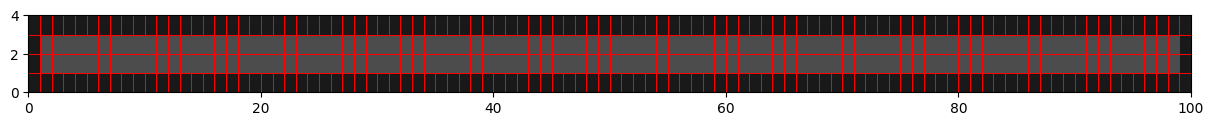

In [2]:
nrows = 4
ncols = 100

shape = (nrows, ncols)

a = np.ones(shape, dtype=np.float32)

mask = (slice(1, -1), slice(1, -1))

baseline_value = 3

a[mask] = baseline_value

fig = plt.figure(figsize=(15, 1))
plt.pcolormesh(a, edgecolors="r", linewidth=0.5, cmap="gray", vmin=0, vmax=10)

In [3]:
prop_length = a[mask].shape[1]

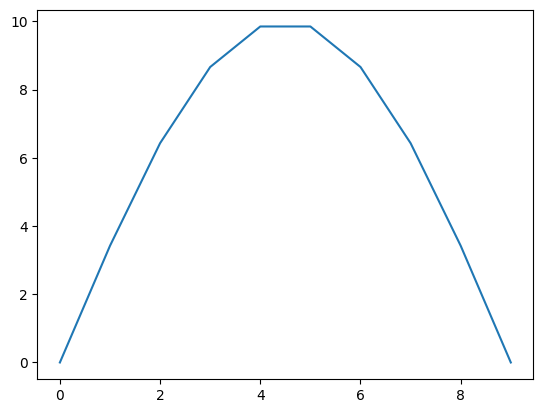

In [4]:
# wave = np.array([0.3, 1, 1, 1, 1, 1, 1, 0.3]) * 10
wave = np.sin(np.linspace(0, np.pi, 10)) * 10
plt.plot(wave)

In [5]:
wave.shape

(10,)

In [6]:
n_frames = prop_length + wave.size

pseudo_length = prop_length + wave.size
movie_clean = np.zeros((pseudo_length * 100, a.shape[0], a.shape[1]))

loc = 0
for i in range(0, movie_clean.shape[0]):
    movie_clean[i] = a.copy()
    
    movie_clean[i][mask] = np.pad(wave, (loc % pseudo_length, prop_length - (loc % pseudo_length) + wave.size), mode="constant", constant_values=baseline_value)[wave.size:-wave.size]
    movie_clean[i] = movie_clean[i]
    # loc += np.random.randint(0, 5)
    loc += 2

# for i in range(pseudo_length, movie_clean.shape[0]):
#     movie_clean[i] = movie_clean[i % pseudo_length]

movie_shape = list(movie_clean.shape)
# movie_shape[1] *= 2

movie_dual = np.zeros(movie_shape)

for i in tqdm(range(movie_dual.shape[0])):
    movie_dual[i] = np.vstack([movie_clean[i]])#, np.fliplr(movie_clean[i])])

movie = np.zeros(movie_dual.shape)

for i in tqdm(range(movie.shape[0])):
    for x in range(movie.shape[1]):
        for y in range(movie.shape[2]):
            movie[i, x, y] = movie_dual[i, x, y] + np.random.normal(scale=4)

100%|█████████████████████████████████████| 10800/10800 [00:10<00:00, 1074.46it/s]


In [10]:
movie.shape

(10800, 4, 100)

In [11]:
iw = fpl.ImageWidget([movie_dual, movie], names=["clean", "noisy input"], grid_shape=(2, 1))
iw.show()

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:34: UserWarning: converting float64 array to float32
  warn(f"converting {array.dtype} array to float32")


JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

In [12]:
class TdSVD:
    def __init__(
        self,
        movie: np.ndarray,
        n_time_steps: int,
        delay: int,
    ):
        self.n_time_steps = n_time_steps
        self.movie_mean = movie.mean(axis=0)
        
        frame = movie[0]
        self.xdim, self.ydim = frame.shape[0], frame.shape[1]
        
        n_pixels = self.xdim * self.ydim
        n_timepoints = movie.shape[0]
        
        self.A = np.zeros((n_pixels * n_time_steps, n_timepoints - n_time_steps), dtype=np.float32)
        A_ixs = np.zeros(n_pixels * n_time_steps)
        
        for pixel_ix, (x, y) in tqdm(enumerate(product(range(self.xdim), range(self.ydim))), total=n_pixels):
            for step in range(n_time_steps):
                self.A[(n_time_steps * pixel_ix) + step] = np.roll(movie[:, x, y], shift=-delay * step)[:-n_time_steps]

        self.k, self.U, self.S, self.V = None, None, None, None
    
    def fit(self, k=6, **kwargs):
        self.k = k
        t0 = time()
        self.U, self.S, self.V = svds(self.A, k=k, **kwargs)
        self.U = self.U[:, ::-1]
        self.S = self.S[::-1]
        self.V = self.V[::-1, :]
        t1 = time()
        print(f"svd took: {t1 - t0:.02f} sec")

    def get_spatial(self):
        """
        Returns
        -------
        np.ndarray
            [n_time_steps, k, ydim, xdim]
        """
        return np.array([self.U.reshape((self.xdim, self.ydim, self.n_time_steps, self.k))[..., i, :].transpose(2, 0, 1) for i in range(self.n_time_steps)])

## Works if: `n_time_steps * delay = propagation_duration`

In [13]:
td_svd = TdSVD(
    movie=movie,
    n_time_steps=5,
    delay=10,
)

100%|█████████████████████████████████████████| 400/400 [00:00<00:00, 4293.29it/s]


In [55]:
td_svd.fit(k=10)

svd took: 1.08 sec


In [56]:
spatial = td_svd.get_spatial()

In [57]:
iw = fpl.ImageWidget(
    data=[spatial[step] for step in range(td_svd.n_time_steps)],
    names=[f"step-{i}" for i in range(td_svd.n_time_steps)],
    grid_plot_kwargs={"size": (1500, 400)}
)
iw.show()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(css_height='400px', css_width='1500px'), IpywidgetToolBar(chi…

In [68]:
td_svd_clean = TdSVD(
    movie=movie_dual,
    n_time_steps=4,
    delay=6,
)

td_svd_clean.fit(k=10)

100%|█████████████████████████████████████████| 400/400 [00:00<00:00, 5650.78it/s]


svd took: 0.70 sec


In [69]:
plot = fpl.Plot()

plot.add_image(td_svd_clean.A)

plot.show()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

<Axes: >

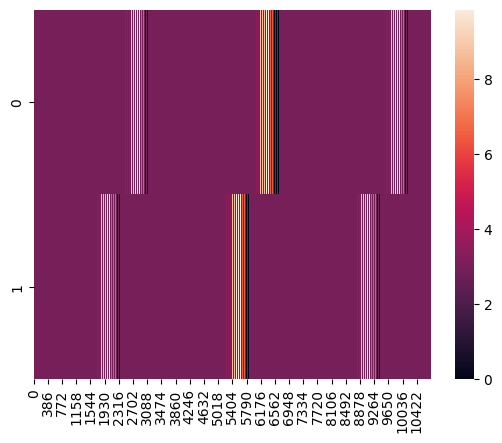

In [81]:
sns.heatmap(td_svd_clean.A[500:502])

In [70]:
spatial = td_svd_clean.get_spatial()

iw_clean = fpl.ImageWidget(
    data=[spatial[step] for step in range(td_svd_clean.n_time_steps)],
    names=[f"step-{i}" for i in range(td_svd_clean.n_time_steps)],
    grid_plot_kwargs={"size": (1500, 400)}
)
iw_clean.show()

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:34: UserWarning: converting float64 array to float32
  warn(f"converting {array.dtype} array to float32")


JupyterOutputContext(children=(JupyterWgpuCanvas(css_height='400px', css_width='1500px'), IpywidgetToolBar(chi…

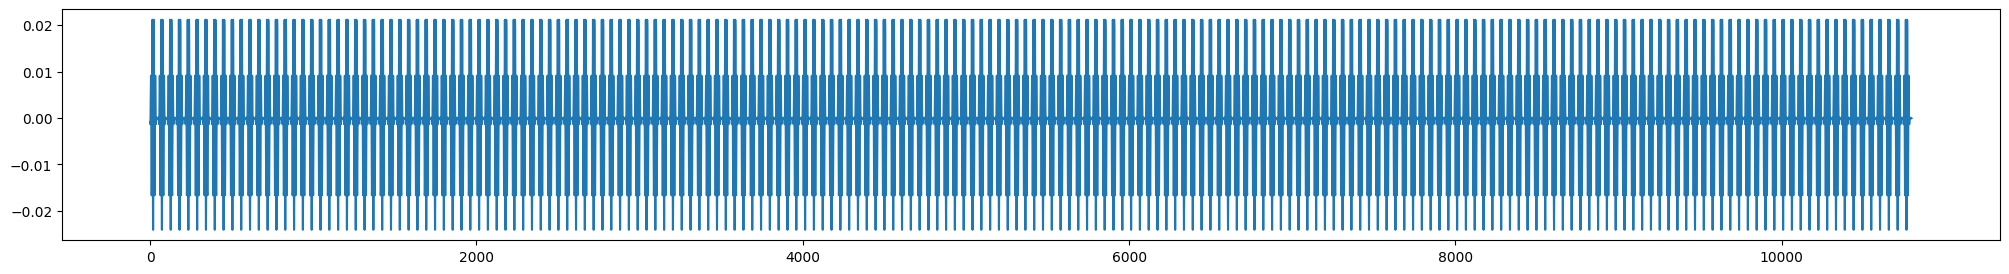

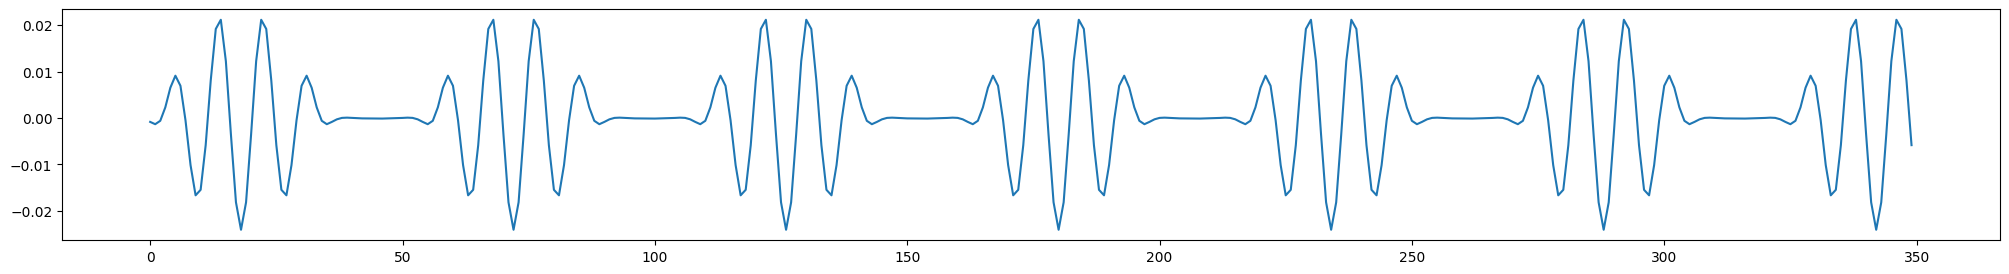

In [75]:
i = 1

fig = plt.figure(figsize=(25, 3))
plt.plot(td_svd_clean.V[i])
plt.show()

fig = plt.figure(figsize=(25, 3))
plt.plot(td_svd_clean.V[i][:350])
plt.show()

In [40]:
iw.cmap = "gnuplot2_r"

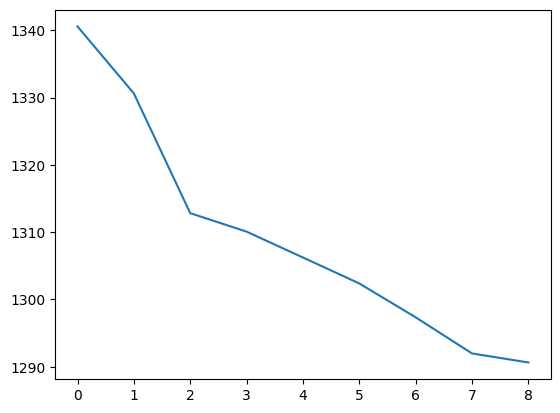

In [32]:
plt.plot(td_svd.S[1:])
# plt.xscale("log")
# plt.yscale("log")

In [33]:
from scipy import signal

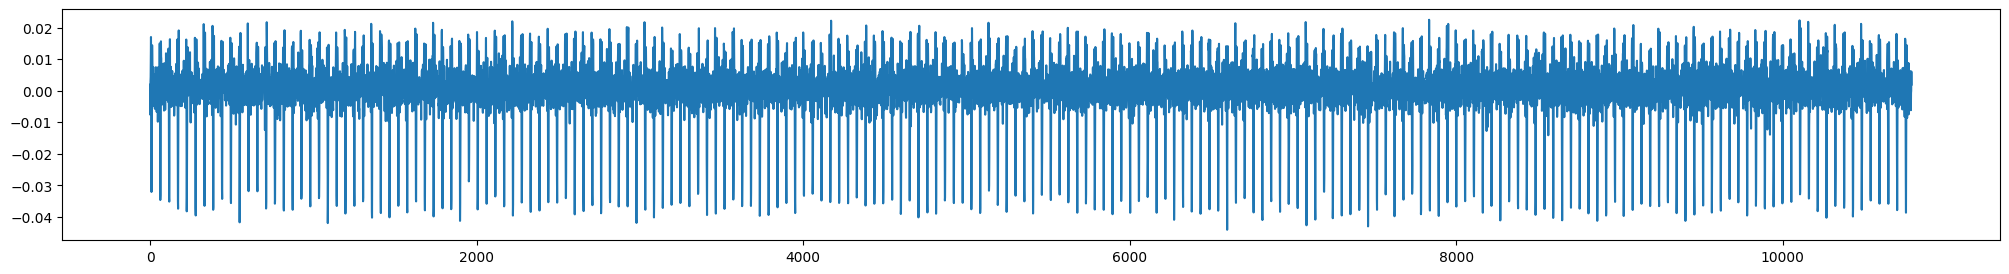

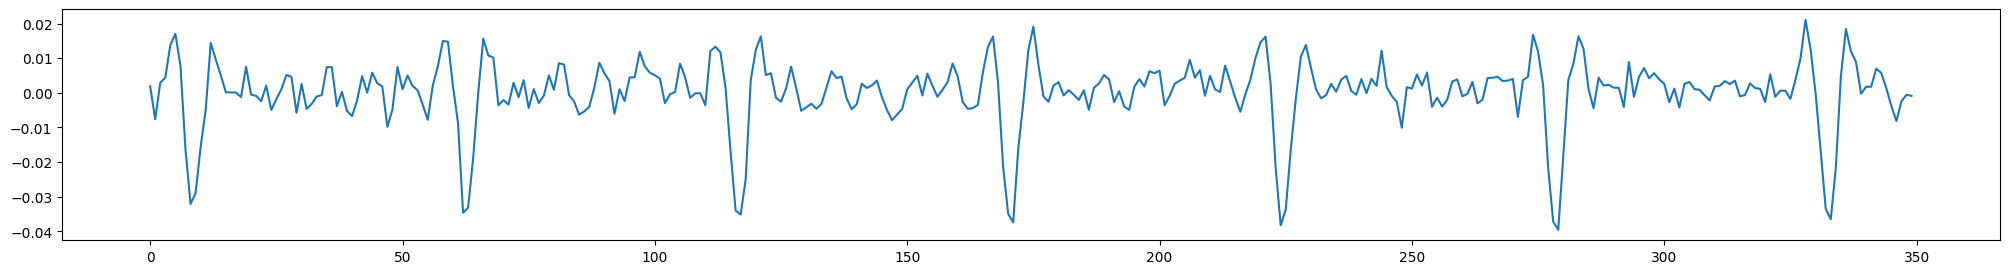

In [34]:
i = 1

fig = plt.figure(figsize=(25, 3))
plt.plot(td_svd.V[i])
plt.show()

fig = plt.figure(figsize=(25, 3))
plt.plot(td_svd.V[i][:350])
plt.show()

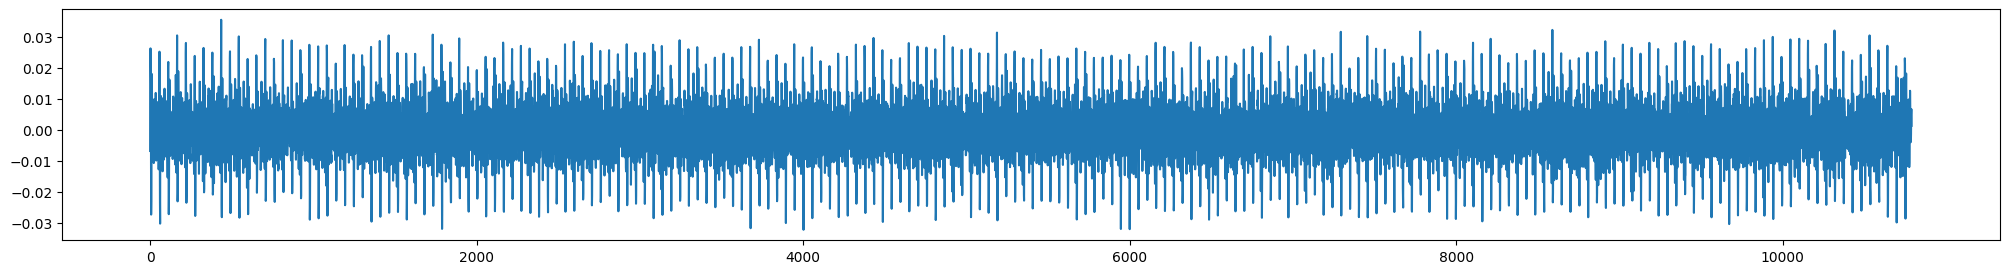

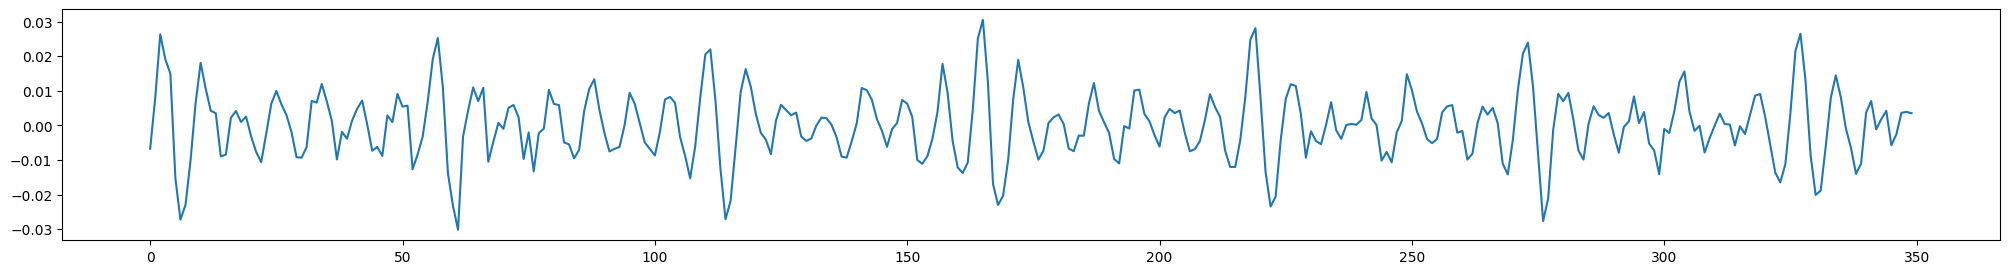

In [26]:
fig = plt.figure(figsize=(25, 3))
plt.plot(td_svd.V[2])
plt.show()

fig = plt.figure(figsize=(25, 3))
plt.plot(td_svd.V[2][:350])
plt.show()

In [19]:
u, s, v = svds(movie.reshape(movie.shape[0], movie.shape[1] * movie.shape[2]).T)
u = u[:, ::-1]
s = s[::-1]
v = v[::-1]

In [20]:
iw = fpl.ImageWidget(
    data=[_.reshape(movie.shape[1], movie.shape[2]) for _ in u.T],
    grid_plot_kwargs={"size": (1500, 400)}
)
iw.show()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(css_height='400px', css_width='1500px'), IpywidgetToolBar(chi…